## Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('../data/processed/rainfall_model_ready.csv')

In [3]:
df = df.sort_values(
    ['YEAR', 'SUBDIVISION']
).reset_index(drop=True)

In [4]:
df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,...,Jun-Sep,Oct-Dec,annual_lag1,annual_lag2,annual_lag3,rolling_mean_3,annual_lag4,annual_lag5,rolling_mean_5,target
0,ANDAMAN & NICOBAR ISLANDS,1906,36.6,0.0,0.0,0.0,556.1,733.3,247.7,320.5,...,1465.8,475.9,2566.7,3079.6,2957.4,2867.900000,3520.7,3373.2,3099.52,3347.9
1,ASSAM & MEGHALAYA,1906,9.7,59.2,88.4,263.5,271.3,388.4,541.8,585.9,...,1780.3,190.8,2790.7,2664.2,2544.6,2666.500000,2952.1,2498.7,2690.06,2521.3
2,BIHAR,1906,14.4,56.9,8.6,0.9,44.7,191.3,366.2,430.1,...,1106.3,33.3,1498.6,1269.7,1016.4,1261.566667,1206.2,952.4,1188.66,1126.4
3,CHHATTISGARH,1906,25.0,91.0,52.5,0.0,4.1,210.1,445.2,258.3,...,1155.9,66.1,1250.9,1492.4,1331.1,1358.133333,923.9,1386.9,1277.04,1308.8
4,COASTAL ANDHRA PRADESH,1906,3.9,23.5,9.9,2.3,11.0,252.6,155.8,241.1,...,776.4,194.4,795.0,860.1,1316.1,990.400000,1063.5,993.7,1005.68,817.9


In [5]:
train_df = df[df['YEAR'] <= 2000].copy()

validation_df = df[
    (df['YEAR'] > 2000) &
    (df['YEAR'] <= 2008)
].copy()

test_df = df[
    (df['YEAR'] > 2008) &
    (df['YEAR'] <= 2014)
].copy()

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain years:", train_df['YEAR'].min(), "to", train_df['YEAR'].max())
print("Validation years:", validation_df['YEAR'].min(), "to", validation_df['YEAR'].max())
print("Test years:", test_df['YEAR'].min(), "to", test_df['YEAR'].max())

Train shape: (3370, 27)
Validation shape: (288, 27)
Test shape: (216, 27)

Train years: 1906 to 2000
Validation years: 2001 to 2008
Test years: 2009 to 2014


In [6]:
feature_cols = [
    'annual_lag1',
    'annual_lag2',
    'annual_lag3',
    'annual_lag4',
    'annual_lag5',
    'rolling_mean_3',
    'rolling_mean_5'
]

target_col = 'target'

In [7]:
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_validation = validation_df[feature_cols]
y_validation = validation_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

In [8]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
test_predictions = linear_model.predict(X_test)

In [10]:
print("Number of test observations:", len(y_test))
print("Number of predictions:", len(test_predictions))

Number of test observations: 216
Number of predictions: 216


In [11]:
test_mae = mean_absolute_error(y_test, test_predictions)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(y_test, test_predictions)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Test MAE: 211.839812519063
Test RMSE: 289.06099919324197
Test R²: 0.8910400567984632


### Actual vs Predicted Rainfall

In [12]:
evaluation_df = test_df[
    ['SUBDIVISION', 'YEAR']
].copy()

evaluation_df['actual'] = y_test.values
evaluation_df['predicted'] = test_predictions

evaluation_df['error'] = (
    evaluation_df['actual'] -
    evaluation_df['predicted']
)

evaluation_df['absolute_error'] = (
    evaluation_df['error'].abs()
)

evaluation_df.head()

,SUBDIVISION,YEAR,actual,predicted,error,absolute_error
3658,ANDAMAN & NICOBAR ISLANDS,2009,3157.1,2815.886523,341.213477,341.213477
3659,ARUNACHAL PRADESH,2009,2855.6,2454.627214,400.972786,400.972786
3660,ASSAM & MEGHALAYA,2009,2711.4,2490.538615,220.861385,220.861385
3661,BIHAR,2009,629.2,1217.704300,-588.504300,588.504300
3662,CHHATTISGARH,2009,1306.6,1211.366717,95.233283,95.233283


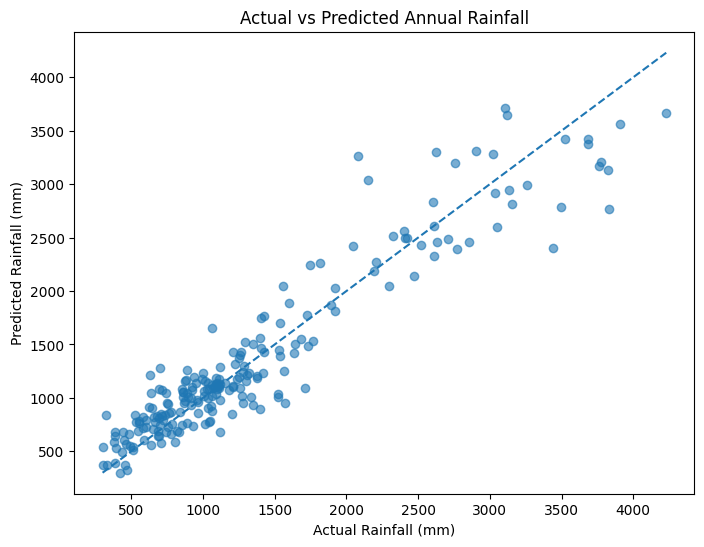

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    evaluation_df['actual'],
    evaluation_df['predicted'],
    alpha=0.6
)

min_value = min(
    evaluation_df['actual'].min(),
    evaluation_df['predicted'].min()
)

max_value = max(
    evaluation_df['actual'].max(),
    evaluation_df['predicted'].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Rainfall (mm)')
plt.ylabel('Predicted Rainfall (mm)')
plt.title('Actual vs Predicted Annual Rainfall')
plt.show()

### Residual Analysis

In [15]:
print("Mean Error:", evaluation_df['error'].mean())
print("Mean Absolute Error:", evaluation_df['absolute_error'].mean())
print("Minimum Error:", evaluation_df['error'].min())
print("Maximum Error:", evaluation_df['error'].max())

Mean Error: -15.683346623029221
Mean Absolute Error: 211.839812519063
Minimum Error: -1179.4259249632387
Maximum Error: 1060.6928169162757


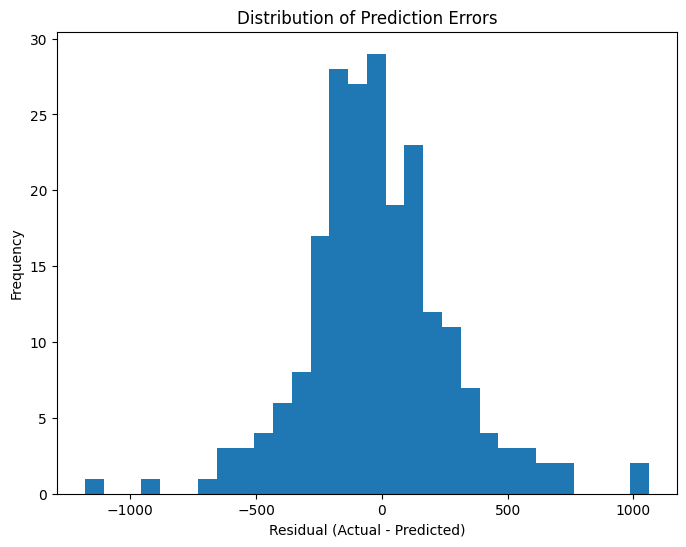

In [16]:
plt.figure(figsize=(8, 6))

plt.hist(
    evaluation_df['error'],
    bins=30
)

plt.xlabel('Residual (Actual - Predicted)')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')

plt.show()

### Largest Error Identification

In [17]:
largest_errors = evaluation_df.sort_values(
    'absolute_error',
    ascending=False
)

largest_errors[
    [
        'SUBDIVISION',
        'YEAR',
        'actual',
        'predicted',
        'error',
        'absolute_error'
    ]
].head(10)

,SUBDIVISION,YEAR,actual,predicted,error,absolute_error
3855,KONKAN & GOA,2014,2081.8,3261.225925,-1179.425925,1179.425925
3694,ANDAMAN & NICOBAR ISLANDS,2010,3828.0,2767.307183,1060.692817,1060.692817
3731,ARUNACHAL PRADESH,2011,3440.5,2404.720967,1035.779033,1035.779033
3746,KERALA,2011,2151.2,3042.513442,-891.313442,891.313442
3730,ANDAMAN & NICOBAR ISLANDS,2011,3497.6,2788.573226,709.026774,709.026774
3711,KONKAN & GOA,2010,3825.2,3127.678280,697.521720,697.521720
3802,ANDAMAN & NICOBAR ISLANDS,2013,2622.5,3296.053400,-673.553400,673.553400
3663,COASTAL ANDHRA PRADESH,2009,1712.5,1089.473002,623.026998,623.026998
3852,JAMMU & KASHMIR,2014,1572.9,954.951643,617.948357,617.948357
3844,COASTAL KARNATAKA,2014,3105.9,3715.915637,-610.015637,610.015637


In [18]:
evaluation_df['error'].describe()

count     216.000000
mean      -15.683347
std       289.305692
min     -1179.425925
25%      -169.006201
50%       -35.294049
75%       130.887363
max      1060.692817
Name: error, dtype: float64

In [19]:
print(
    "Underpredictions:",
    (evaluation_df['error'] > 0).sum()
)

print(
    "Overpredictions:",
    (evaluation_df['error'] < 0).sum()
)

Underpredictions: 92
Overpredictions: 124


### Subdivision-wise Performance

In [20]:
subdivision_performance = (
    evaluation_df
    .groupby('SUBDIVISION')
    .apply(
        lambda group: pd.Series({
            'MAE': mean_absolute_error(
                group['actual'],
                group['predicted']
            ),
            'RMSE': np.sqrt(
                mean_squared_error(
                    group['actual'],
                    group['predicted']
                )
            )
        })
    )
    .reset_index()
)

subdivision_performance

C:\Users\HP\AppData\Local\Temp\ipykernel_12928\3512372300.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,SUBDIVISION,MAE,RMSE
0,ANDAMAN & NICOBAR ISLANDS,629.250926,671.651505
1,ARUNACHAL PRADESH,392.902822,507.731623
2,ASSAM & MEGHALAYA,307.360313,339.508381
3,BIHAR,134.250832,245.151021
4,CHHATTISGARH,134.008889,143.494716
5,COASTAL ANDHRA PRADESH,221.832753,297.487516
6,COASTAL KARNATAKA,436.256002,456.490746
7,EAST MADHYA PRADESH,218.708510,268.472217
8,EAST RAJASTHAN,87.735517,113.461074
9,EAST UTTAR PRADESH,127.466332,151.415589


In [21]:
print("Highest MAE:")
display(
    subdivision_performance
    .sort_values('MAE', ascending=False)
    .head(10)
)

print("Lowest MAE:")
display(
    subdivision_performance
    .sort_values('MAE')
    .head(10)
)

Highest MAE:


,SUBDIVISION,MAE,RMSE
0,ANDAMAN & NICOBAR ISLANDS,629.250926,671.651505
17,KONKAN & GOA,542.905434,642.500491
6,COASTAL KARNATAKA,436.256002,456.490746
1,ARUNACHAL PRADESH,392.902822,507.731623
16,KERALA,354.536403,439.825339
2,ASSAM & MEGHALAYA,307.360313,339.508381
26,SAURASHTRA & KUTCH,276.712771,317.842465
14,JAMMU & KASHMIR,256.490636,320.038761
30,TELANGANA,224.734452,258.478465
10,GANGETIC WEST BENGAL,222.790391,279.826659


Lowest MAE:


,SUBDIVISION,MAE,RMSE
34,WEST RAJASTHAN,77.951435,91.348912
8,EAST RAJASTHAN,87.735517,113.461074
24,PUNJAB,100.282515,120.518816
13,HIMACHAL PRADESH,103.643323,121.618894
12,HARYANA DELHI & CHANDIGARH,104.196504,127.235082
28,SUB HIMALAYAN WEST BENGAL & SIKKIM,104.545363,121.806433
27,SOUTH INTERIOR KARNATAKA,107.063914,138.644743
9,EAST UTTAR PRADESH,127.466332,151.415589
31,UTTARAKHAND,132.309465,175.301784
4,CHHATTISGARH,134.008889,143.494716


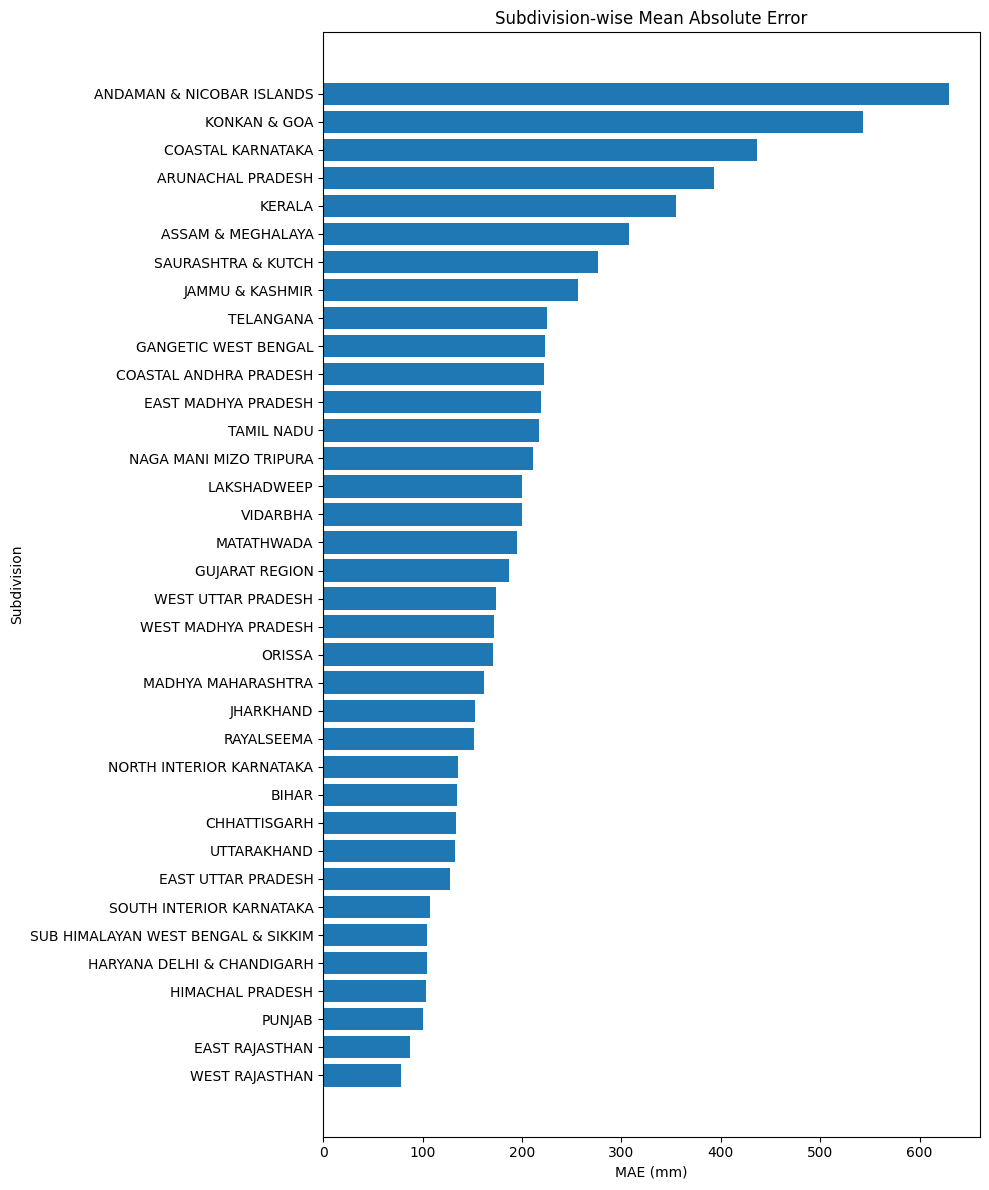

In [22]:
plot_data = subdivision_performance.sort_values(
    'MAE',
    ascending=True
)

plt.figure(figsize=(10, 12))

plt.barh(
    plot_data['SUBDIVISION'],
    plot_data['MAE']
)

plt.xlabel('MAE (mm)')
plt.ylabel('Subdivision')
plt.title('Subdivision-wise Mean Absolute Error')

plt.tight_layout()
plt.show()

### Extreme Rainfall

In [23]:
extreme_rainfall = evaluation_df.sort_values(
    'actual',
    ascending=False
)

extreme_rainfall[
    [
        'SUBDIVISION',
        'YEAR',
        'actual',
        'predicted',
        'error',
        'absolute_error'
    ]
].head(10)

,SUBDIVISION,YEAR,actual,predicted,error,absolute_error
3772,COASTAL KARNATAKA,2012,4229.5,3666.526428,562.973572,562.973572
3700,COASTAL KARNATAKA,2010,3908.6,3563.649140,344.950860,344.950860
3694,ANDAMAN & NICOBAR ISLANDS,2010,3828.0,2767.307183,1060.692817,1060.692817
3711,KONKAN & GOA,2010,3825.2,3127.678280,697.521720,697.521720
3675,KONKAN & GOA,2009,3778.1,3206.713850,571.386150,571.386150
3766,ANDAMAN & NICOBAR ISLANDS,2012,3757.7,3167.993810,589.706190,589.706190
3664,COASTAL KARNATAKA,2009,3686.7,3373.813719,312.886281,312.886281
3808,COASTAL KARNATAKA,2013,3684.5,3423.242706,261.257294,261.257294
3783,KONKAN & GOA,2012,3523.9,3418.361520,105.538480,105.538480
3730,ANDAMAN & NICOBAR ISLANDS,2011,3497.6,2788.573226,709.026774,709.026774


In [24]:
correlation = evaluation_df[
    ['actual', 'absolute_error']
].corr().iloc[0, 1]

print("Correlation between actual rainfall and absolute error:",
      correlation)

Correlation between actual rainfall and absolute error: 0.47221588942465037


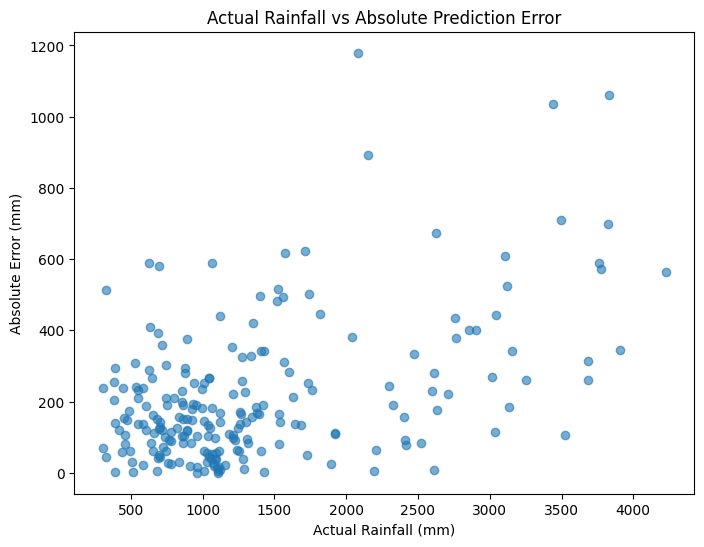

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    evaluation_df['actual'],
    evaluation_df['absolute_error'],
    alpha=0.6
)

plt.xlabel('Actual Rainfall (mm)')
plt.ylabel('Absolute Error (mm)')
plt.title('Actual Rainfall vs Absolute Prediction Error')

plt.show()

In [26]:
median_rainfall = evaluation_df['actual'].median()

low_rainfall = evaluation_df[
    evaluation_df['actual'] <= median_rainfall
]

high_rainfall = evaluation_df[
    evaluation_df['actual'] > median_rainfall
]

print("Median actual rainfall:", median_rainfall)

print("\nLow rainfall group")
print("Count:", len(low_rainfall))
print("MAE:", low_rainfall['absolute_error'].mean())

print("\nHigh rainfall group")
print("Count:", len(high_rainfall))
print("MAE:", high_rainfall['absolute_error'].mean())

Median actual rainfall: 1084.5500000000002

Low rainfall group
Count: 108
MAE: 158.13139920425166

High rainfall group
Count: 108
MAE: 265.54822583387437


In [27]:
subdivision_performance_normalized = (
    evaluation_df
    .groupby('SUBDIVISION')
    .apply(
        lambda group: pd.Series({
            'MAE': mean_absolute_error(
                group['actual'],
                group['predicted']
            ),
            'RMSE': np.sqrt(
                mean_squared_error(
                    group['actual'],
                    group['predicted']
                )
            ),
            'Mean_Actual_Rainfall': group['actual'].mean()
        })
    )
    .reset_index()
)

subdivision_performance_normalized['Normalized_MAE_%'] = (
    subdivision_performance_normalized['MAE']
    / subdivision_performance_normalized['Mean_Actual_Rainfall']
    * 100
)

subdivision_performance_normalized.sort_values(
    'Normalized_MAE_%',
    ascending=False
).head(10)

C:\Users\HP\AppData\Local\Temp\ipykernel_12928\221642185.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,SUBDIVISION,MAE,RMSE,Mean_Actual_Rainfall,Normalized_MAE_%
26,SAURASHTRA & KUTCH,276.712771,317.842465,615.533333,44.954961
20,MATATHWADA,195.220175,209.238966,695.166667,28.082499
35,WEST UTTAR PRADESH,173.454235,183.757126,664.966667,26.084651
14,JAMMU & KASHMIR,256.490636,320.038761,1074.300000,23.875141
29,TAMIL NADU,216.970871,263.603665,919.633333,23.593193
12,HARYANA DELHI & CHANDIGARH,104.196504,127.235082,457.683333,22.766069
30,TELANGANA,224.734452,258.478465,998.416667,22.509085
11,GUJARAT REGION,187.234465,215.049315,856.666667,21.856163
34,WEST RAJASTHAN,77.951435,91.348912,394.950000,19.737039
22,NORTH INTERIOR KARNATAKA,135.322890,154.589319,687.333333,19.688102


## Final Model Evaluation Summary